# 3 · Is it the pumping or the weather? 55 years of groundwater levels in the Netherlands

**KAI Water & Energy case studies** · [Interactive version on the KAI platform](https://hydro-saas.charkaks0.workers.dev/demo/reference/boreholes) · [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free)

Every borehole owner eventually asks: *the level is falling; is it us, our neighbours, or a dry year?* A long
record of water levels, rainfall, evaporation and pumping can answer that, with a time-series model that
learns how the level responds to each of them.

Here you will:

1. load a real 55-year record (1960–2015) of one observation well with four public-supply well fields pumping nearby;
2. build a [Pastas](https://github.com/pastas/pastas) model: recharge from rain minus evaporation, plus one response per well field;
3. **test it blind**: fit 1960–1999 only, then predict 2000–2015 and compare with what was measured;
4. split the observed level into the part caused by each well field and the part caused by the weather.

Runtime: about two minutes.

## The data

From the Pastas documentation (MIT licence, commit `76d347e`, example notebook 10), vendored unchanged in
`data/groundwater-record/`:

| File | What | Units |
|---|---|---|
| `Observation_well.csv` | groundwater head in one observation well, 1960–2015 | m |
| `Precipitation.csv`, `Evaporation.csv` | daily rainfall and reference evaporation | m/day |
| `Extraction 1–4.csv` | monthly pumping of four well fields | m³/day |

In [1]:
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pastas as ps

ps.set_log_level("ERROR")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
D = Path("data/groundwater-record")
read = lambda f: pd.read_csv(D / f, index_col=0, parse_dates=[0]).squeeze("columns").astype(float)

head = read("Observation_well.csv").rename("head")
prec = read("Precipitation.csv"); prec.index = prec.index.round("D")
evap = read("Evaporation.csv"); evap.index = evap.index.round("D")
wells = {}
for i in range(1, 5):
    s = read(f"Extraction {i}.csv")
    s.index = s.index.to_period("M").to_timestamp("M")
    daily = ps.ts.time_weighted_resample(s, pd.date_range(s.index[0], s.index[-1], freq="D")).dropna()
    wells[f"wellfield_{i}"] = daily.rename(f"wellfield_{i}")
print(f"Pastas {ps.__version__} | {head.size} level readings, {head.index.min():%Y-%m-%d} to {head.index.max():%Y-%m-%d}")

Pastas 2.0.0 | 2846 level readings, 1960-04-28 to 2015-06-29


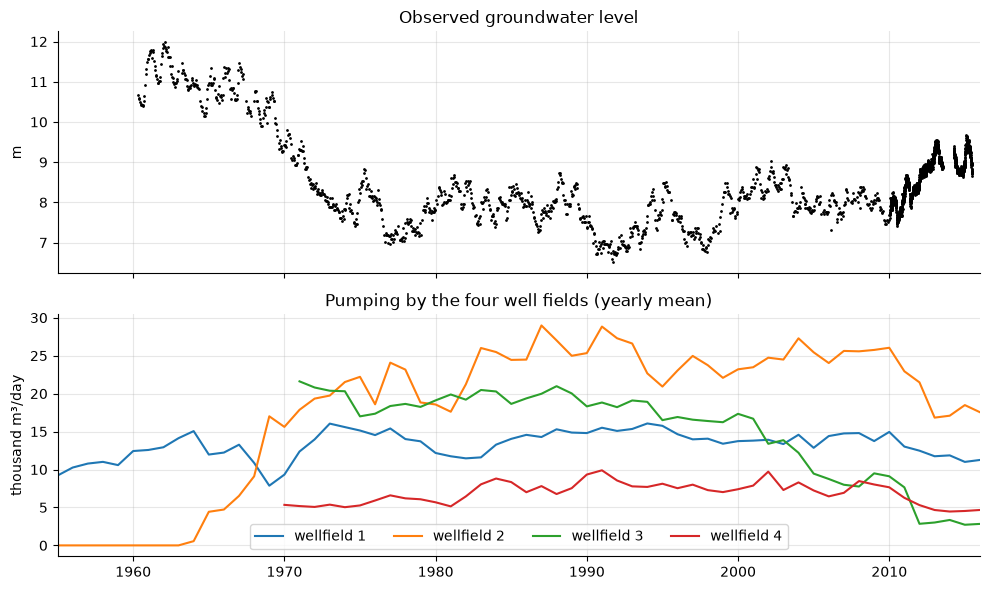

In [2]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.plot(head.index, head.values, ".", ms=2, color="k")
a1.set(ylabel="m", title="Observed groundwater level")
for n, s in wells.items():
    y = s.resample("YE").mean() / 1000
    a2.plot(y.index, y.values, label=n.replace("_", " "))
a2.set(ylabel="thousand m³/day", title="Pumping by the four well fields (yearly mean)")
a2.legend(ncol=4); a2.set_xlim(pd.Timestamp("1955"), pd.Timestamp("2016"))
plt.tight_layout()

## The model

* **Recharge:** rainfall minus a fitted fraction of evaporation, passed through a Gamma response (how the
  water table answers a wet day over the following weeks).
* **Each well field:** a Hantush response, the time-series counterpart of the leaky-aquifer solution of
  notebook 1. Pumping is entered in million m³/day so the parameters are of similar size.
* **Noise:** an autoregressive model for what the stresses cannot explain.

In [3]:
def build_model(with_wells=True):
    ml = ps.Model(head, name="wells" if with_wells else "weather only")
    ps.ArNoiseModel(ml)
    ps.RechargeModel(ml, prec, evap, rfunc=ps.Gamma(), name="recharge")
    if with_wells:
        for n, q in wells.items():
            ps.StressModel(ml, q / 1e6, rfunc=ps.Hantush(), name=n, settings="well", up=False)
    return ml

def monthly_skill(sim, obs):
    o = obs.resample("ME").mean().dropna()
    s = sim.resample("ME").mean().reindex(o.index)
    e = (s - o).dropna()
    return {"RMSE (m)": float(np.sqrt(np.mean(e ** 2))), "bias (m)": float(e.mean()), "months": int(e.size)}

T0, TRAIN_END, T1 = str(head.index.min().date()), "1999-12-31", str(head.index.max().date())

## The blind test

Fit only on 1960–1999. Then simulate 2000–2015 from rainfall, evaporation and pumping alone, and compare with
the levels that were actually measured. Two baselines: a model that knows only the weather, and the simplest
guess an operator could make (the mean of the last five years before 2000).

In [4]:
ml_tr = build_model(True); ml_tr.solve(tmin=T0, tmax=TRAIN_END, report=False)
wx_tr = build_model(False); wx_tr.solve(tmin=T0, tmax=TRAIN_END, report=False)
sim_tr = ml_tr.simulate(tmin=T0, tmax=T1)
sim_wx = wx_tr.simulate(tmin=T0, tmax=T1)
test = head[head.index > TRAIN_END]
naive = pd.Series(head["1995":"1999"].mean(), index=sim_tr.index)

skill = pd.DataFrame({
    "weather + four well fields": monthly_skill(sim_tr[TRAIN_END:], test),
    "weather only": monthly_skill(sim_wx[TRAIN_END:], test),
    "mean of 1995–1999": monthly_skill(naive[TRAIN_END:], test),
}).T
skill.style.format({"RMSE (m)": "{:.2f}", "bias (m)": "{:+.2f}", "months": "{:.0f}"})

,RMSE (m),bias (m),months
weather + four well fields,0.22,+0.13,175
weather only,0.77,+0.62,175
mean of 1995–1999,0.85,-0.71,175


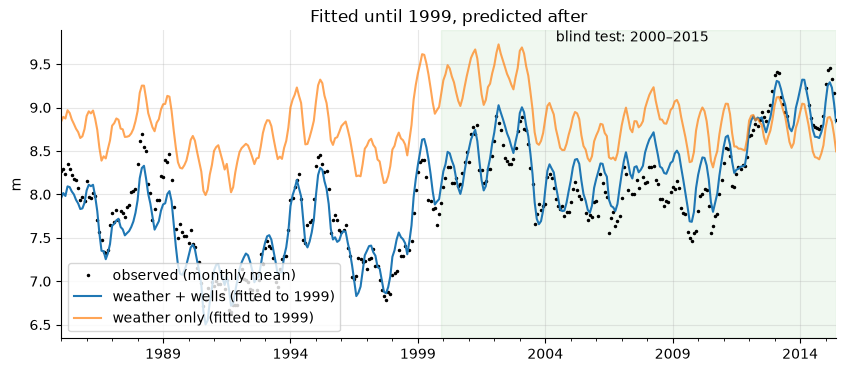

In [5]:
fig, ax = plt.subplots()
o = head.resample("ME").mean()
o["1985":].plot(ax=ax, style=".", color="k", ms=3, label="observed (monthly mean)")
sim_tr.resample("ME").mean()["1985":].plot(ax=ax, label="weather + wells (fitted to 1999)")
sim_wx.resample("ME").mean()["1985":].plot(ax=ax, alpha=0.7, label="weather only (fitted to 1999)")
ax.axvspan(pd.Timestamp(TRAIN_END), pd.Timestamp(T1), color="tab:green", alpha=0.07)
ax.text(pd.Timestamp("2007-06-01"), ax.get_ylim()[1], "blind test: 2000–2015", va="top", ha="center")
ax.set(ylabel="m", title="Fitted until 1999, predicted after")
ax.legend(loc="lower left");

Knowing the pumping matters: the model with the well fields predicts 15 years ahead to about two decimetres
(RMSE of monthly means);
the weather-only model drifts by more than half a metre, because it cannot see how the pumping changed.

## Who lowered the water table?

Now fit the whole record and split the simulated level into its parts. Each well field's **contribution** is
how much lower the level is because that well field pumps.

Explained variance 95.6 %, RMSE 0.19 m
At the peak, in 1991, the four well fields together held the level 6.0 m lower.
Weather moves the yearly level by -0.5 to +0.5 m (5th–95th percentile).


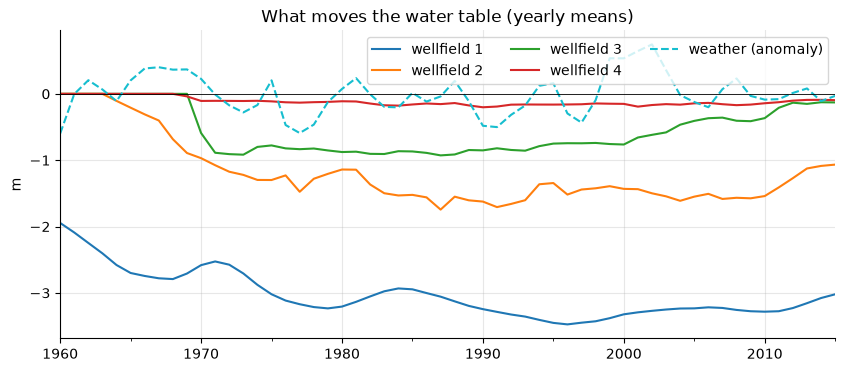

In [6]:
ml = build_model(True); ml.solve(tmin=T0, tmax=T1, report=False)
print(f"Explained variance {ml.stats.evp():.1f} %, RMSE {ml.stats.rmse():.2f} m")
parts = {n: ml.get_contribution(n, tmin=T0, tmax=T1) for n in ["recharge", *wells]}
yearly = pd.DataFrame({k: v.resample("YE").mean() for k, v in parts.items()})
wells_total = yearly[list(wells)].sum(axis=1)

fig, ax = plt.subplots()
for n in wells:
    yearly[n].plot(ax=ax, label=n.replace("_", " "))
(yearly["recharge"] - parts["recharge"].mean()).plot(ax=ax, color="tab:cyan", ls="--", label="weather (anomaly)")
ax.axhline(0, color="k", lw=0.6)
ax.set(ylabel="m", title="What moves the water table (yearly means)")
ax.legend(ncol=3);
peak = wells_total.idxmin()
print(f"At the peak, in {peak.year}, the four well fields together held the level {-wells_total.min():.1f} m lower.")
rch = parts["recharge"].resample("YE").mean()
print(f"Weather moves the yearly level by {np.percentile(rch - rch.mean(), 5):+.1f} to {np.percentile(rch - rch.mean(), 95):+.1f} m (5th–95th percentile).")

In [7]:
rows = []
for n in wells:
    p = ml.get_parameters(n)
    gain = ml.stressmodels[n].rfunc.gain(p)            # m per (million m³/day), negative = drawdown
    rows.append({"well field": n.replace("_", " "), "drawdown per 1,000 m³/day (m)": -gain / 1000})
pd.DataFrame(rows).style.format(precision=3).hide(axis="index")

well field,"drawdown per 1,000 m³/day (m)"
wellfield 1,0.231
wellfield 2,0.061
wellfield 3,0.045
wellfield 4,0.021


Well field 1 has by far the strongest effect on this well: every 1,000 m³/day it pumps lowers the level by about a
quarter of a metre in the long run, several times more than any other well field (the estimate for well field 4
is small and uncertain). That is the number a utility needs when it decides **which** well field to throttle in a
dry year.

## Compare with the KAI engine

In [8]:
kai = json.loads(Path("results/kai_engine_results.json").read_text())["record"]
v = kai["validation"]
assert abs(skill.loc["weather + four well fields", "RMSE (m)"] - v["weather_and_wells"]["rmse"]) < 0.02, "blind-test RMSE differs from the published KAI result"
pd.DataFrame([
    {"result": "blind test RMSE, weather + wells (m)", "this notebook": skill.loc["weather + four well fields", "RMSE (m)"], "KAI engine": v["weather_and_wells"]["rmse"]},
    {"result": "blind test RMSE, weather only (m)", "this notebook": skill.loc["weather only", "RMSE (m)"], "KAI engine": v["weather_only"]["rmse"]},
    {"result": "peak drawdown by the well fields (m)", "this notebook": -wells_total.min(), "KAI engine": kai["peak_wells_drawdown_m"]},
    {"result": "well field 1, m per 1,000 m³/day", "this notebook": rows[0]["drawdown per 1,000 m³/day (m)"], "KAI engine": kai["gains"]["Extraction_1"]["m_per_1000m3d"]},
]).style.format({"this notebook": "{:.2f}", "KAI engine": "{:.2f}"}).hide(axis="index")

result,this notebook,KAI engine
"blind test RMSE, weather + wells (m)",0.22,0.22
"blind test RMSE, weather only (m)",0.77,0.77
peak drawdown by the well fields (m),6.01,6.01
"well field 1, m per 1,000 m³/day",0.23,0.23


---

**On the KAI platform**

* [Borehole case, interactive](https://hydro-saas.charkaks0.workers.dev/demo/reference/boreholes): the 55-year record, the blind test and the split by well field.
* [HydroSaaS](https://kai-water.charkaks0.workers.dev/hydrosaas.html) runs this kind of model on a park's own borehole loggers and pumping records,
  and warns before a borehole reaches its safe level.
* [Start free](https://hydro-saas.charkaks0.workers.dev/portal?plan=hydrosaas:free) · [Send us your borehole records](https://kai-water.charkaks0.workers.dev/contact.html)

*Code: MIT. Text and figures: CC BY 4.0, KAI Water & Energy. Data: Pastas documentation (MIT).*